# Занятие № 5. Дискретные случайные величины и их числовые характеристики. Независимость
Условия взяты из `Практические занятия Листок 5.pdf`. Ответы сверяются с листком через `assert` там, где ответ напечатан.

In [1]:
%matplotlib inline
import itertools
from fractions import Fraction as F
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson
rng = np.random.default_rng(2026)

def conv_all(*pmfs):
    '''Распределение суммы независимых величин: словари {значение: вероятность}.'''
    res = {0:F(1)}
    for pmf in pmfs:
        new = {}
        for a,pa in res.items():
            for b,pb in pmf.items():
                new[a+b] = new.get(a+b,0)+pa*pb
        res = new
    return res

def running_mean(values, exact, title, fname=None):
    '''График среднего значения в зависимости от числа экспериментов.'''
    means = np.cumsum(values)/np.arange(1,len(values)+1)
    fig,ax = plt.subplots(figsize=(8,3.2))
    ax.plot(np.arange(1,len(values)+1),means,lw=.9,label='выборочное среднее'); ax.axhline(exact,color='r',lw=1,label=f'точное значение {exact:.4f}')
    ax.set_xscale('log'); ax.set_xlabel('число экспериментов'); ax.grid(True,alpha=.5); ax.legend(); ax.set_title(title)
    if fname: fig.savefig(f'fig/{fname}.png',dpi=120,bbox_inches='tight')
    plt.show()
    return means[-1]

OUTCOMES = np.array(list(itertools.product(range(1,7),repeat=4)))   # все 6^4 исхода для четырёх костей

**5.1.** $X$ принимает значения $1,\dots,6$; $Y_n$ — остаток от деления $X$ на $n$. Независимы ли $Y_2$ и $Y_3$: а) при равновероятном $X$; б) при $P(X=k)=Ak$? Найти ковариацию.

Значениям $X$ соответствуют пары $(Y_2,Y_3)$: $1\to(1,1)$, $2\to(0,2)$, $3\to(1,0)$, $4\to(0,1)$, $5\to(1,2)$, $6\to(0,0)$. Все шесть пар различны.

**а)** $P(Y_2=i,Y_3=j)=\tfrac16=\tfrac12\cdot\tfrac13$, поэтому величины **независимы**, ковариация равна $0$.

**б)** Здесь $A=\tfrac1{21}$. Например, $P(Y_2=0,Y_3=0)=P(X=6)=\tfrac{6}{21}$, а $P(Y_2=0)P(Y_3=0)=\tfrac{12}{21}\cdot\tfrac{9}{21}=\tfrac{108}{441}\ne\tfrac{126}{441}$. Величины **зависимы**. Ковариация вычислена точно:

In [2]:
def analyze(prob):
    Ey2 = sum(p*(k%2) for k,p in prob.items()); Ey3 = sum(p*(k%3) for k,p in prob.items())
    Eyy = sum(p*(k%2)*(k%3) for k,p in prob.items())
    indep = all(sum(p for k,p in prob.items() if k%2==i and k%3==j)
                ==sum(p for k,p in prob.items() if k%2==i)*sum(p for k,p in prob.items() if k%3==j)
                for i in range(2) for j in range(3))
    return indep,Eyy-Ey2*Ey3

print('равновероятно:',analyze({k:F(1,6) for k in range(1,7)}))
ind,cov = analyze({k:F(k,21) for k in range(1,7)})
print('P(X=k)=k/21: независимы =',ind,', cov =',cov,'=',float(cov))

равновероятно: (True, Fraction(0, 1))
P(X=k)=k/21: независимы = False , cov = 20/147 = 0.1360544217687075


**5.2.** Независимые $X\in\{0..12\}$ (равномерно), $Y\in\{0..13\}$ (равномерно), $Z\in\{3,7\}$, $P(Z=3)=\tfrac9{10}$. Найти: а) $P(X+Y+Z=12)$; б) наиболее вероятное значение суммы; в) распределение суммы.

P(S=12) = 24/455 = 0.05274725274725275
мода = 16 , P = 127/1820 = 0.06978021978021978


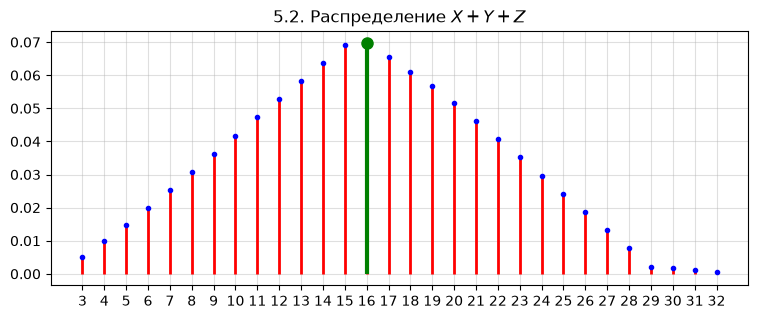

{3: 0.00495, 4: 0.00989, 5: 0.01484, 6: 0.01978, 7: 0.02527, 8: 0.03077, 9: 0.03626, 10: 0.04176, 11: 0.04725, 12: 0.05275, 13: 0.05824, 14: 0.06374, 15: 0.06923, 16: 0.06978, 17: 0.06538, 18: 0.06099, 19: 0.05659, 20: 0.05165, 21: 0.04615, 22: 0.04066, 23: 0.03516, 24: 0.02967, 25: 0.02418, 26: 0.01868, 27: 0.01319, 28: 0.00769, 29: 0.0022, 30: 0.00165, 31: 0.0011, 32: 0.00055}


In [3]:
X = {i:F(1,13) for i in range(13)}; Y = {i:F(1,14) for i in range(14)}; Z = {3:F(9,10),7:F(1,10)}
S = conv_all(X,Y,Z)
assert sum(S.values())==1
M = max(S,key=S.get)
print('P(S=12) =',S[12],'=',float(S[12])); print('мода =',M,', P =',S[M],'=',float(S[M]))
assert abs(float(S[12])-0.05274725274725277)<1e-12 and M==16 and abs(float(S[M])-0.0697802197802198)<1e-12
xs = sorted(S); ps = [float(S[x]) for x in xs]
fig,ax = plt.subplots(figsize=(9,3.3)); ax.vlines(xs,0,ps,color='r',lw=2); ax.vlines(M,0,float(S[M]),color='g',lw=3); ax.plot(xs,ps,'b.'); ax.plot(M,float(S[M]),'o',color='g',ms=8)
ax.set_xticks(xs); ax.grid(True,alpha=.4); ax.set_title('5.2. Распределение $X+Y+Z$'); fig.savefig('fig/Sol_5_2.png',dpi=120,bbox_inches='tight'); plt.show()
print({k:round(float(v),5) for k,v in sorted(S.items())})

**5.3.** Независимые $X$ ($1..13$), $Y$ ($1..12$), $Z$ ($1..8$) с вероятностями, пропорциональными значению. Найти $P(X,Y,Z\text{ различны})$.

In [4]:
pX = {i:F(i,sum(range(1,14))) for i in range(1,14)}; pY = {j:F(j,sum(range(1,13))) for j in range(1,13)}; pZ = {k:F(k,sum(range(1,9))) for k in range(1,9)}
P = sum(pX[i]*pY[j]*pZ[k] for i in pX for j in pY for k in pZ if len({i,j,k})==3)
print(P,'=',float(P)); assert abs(float(P)-0.7836479759556683)<1e-12

16687/21294 = 0.7836479759556683


**5.4.** Четыре кости, $X$ — минимум. Найти $E(X)$, $\operatorname{Var}(X)$, ковариацию числа очков на одной кости и минимума; смоделировать.

**Аналитически.** $P(X\geqslant k)=\left(\dfrac{7-k}{6}\right)^4$, поэтому
$$E(X)=\sum_{k=1}^6P(X\geqslant k)=\frac{6^4+5^4+4^4+3^4+2^4+1^4}{6^4}=\frac{2275}{1296}\approx1{,}7554.$$
Дисперсия находится из $P(X=k)=P(X\geqslant k)-P(X\geqslant k+1)$. Ковариацию считаем точным перебором всех $6^4$ исходов.

E(X)=2275/1296=1.7554, Var(X)=1528583/1679616=0.910079, Cov=161/288=0.559028
оценка cov по симуляции: 0.5532219609598045


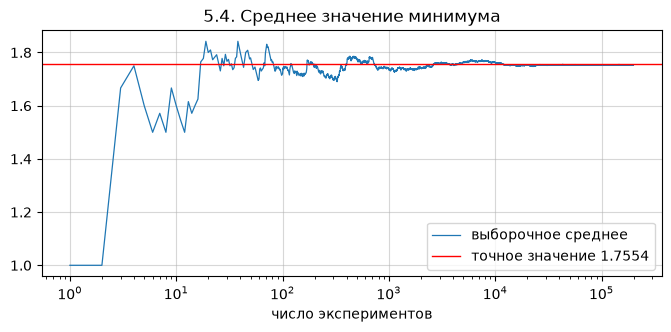

среднее по симуляции: 1.753435


In [5]:
mn = OUTCOMES.min(axis=1)
E = F(int(mn.sum()),6**4); E2 = F(int((mn**2).sum()),6**4); V = E2-E*E
cov = F(int((OUTCOMES[:,0]*mn).sum()),6**4)-F(7,2)*E
print(f'E(X)={E}={float(E):.4f}, Var(X)={V}={float(V):.6f}, Cov={cov}={float(cov):.6f}')
assert E==F(2275,1296) and round(float(E),4)==1.7554 and round(float(V),6)==0.910079
N = 200000
d = rng.integers(1,7,(N,4)); m = d.min(axis=1)
print('оценка cov по симуляции:',np.cov(d[:,0],m)[0,1])
print('среднее по симуляции:',running_mean(m,float(E),'5.4. Среднее значение минимума','Sol_5_4'))

**5.5.** Четыре кости, $X$ — максимум. Так как $\max=7-\min'$, где $\min'$ — минимум величин $7-X_i$, получаем $E(\max)=7-\dfrac{2275}{1296}=\dfrac{6797}{1296}\approx5{,}2446$ при той же дисперсии.

E=6797/1296=5.2446, Var=0.910079


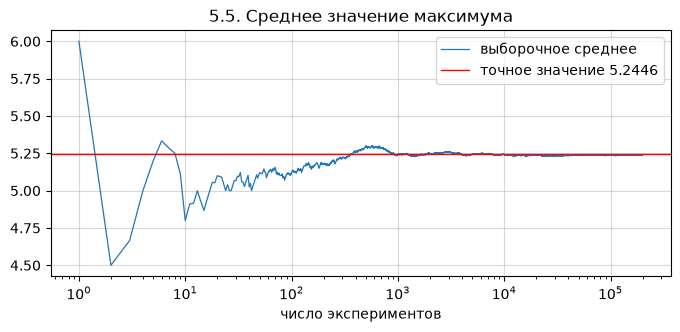

среднее по симуляции: 5.23921


In [6]:
mx = OUTCOMES.max(axis=1)
E = F(int(mx.sum()),6**4); V = F(int((mx**2).sum()),6**4)-E*E
print(f'E={E}={float(E):.4f}, Var={float(V):.6f}'); assert round(float(E),4)==5.2446 and round(float(V),6)==0.910079
print('среднее по симуляции:',running_mean(d.max(axis=1),float(E),'5.5. Среднее значение максимума','Sol_5_5'))

**5.6.** $S$ — сумма трёх наибольших из четырёх костей. $S=X_1+X_2+X_3+X_4-\min$, поэтому $E(S)=14-E(\min)=14-\dfrac{2275}{1296}=\dfrac{15869}{1296}\approx12{,}2446$.

15869/1296 12.244598765432098


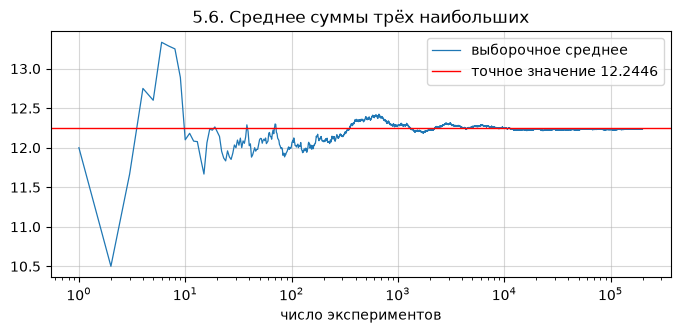

среднее по симуляции: 12.236425


In [7]:
S3 = OUTCOMES.sum(axis=1)-OUTCOMES.min(axis=1)
E = F(int(S3.sum()),6**4); print(E,float(E)); assert E==F(15869,1296)
print('среднее по симуляции:',running_mean(d.sum(axis=1)-d.min(axis=1),float(E),'5.6. Среднее суммы трёх наибольших','Sol_5_6'))

**5.7.** $P(A)=0{,}4$, $P(B)=0{,}3$, $P(C)=0{,}2$; события попарно независимы, но вместе наступить не могут. $V=2X+4Y+6Z$, где $X,Y,Z$ — индикаторы. Найти $E(V)$, $\operatorname{Var}(V)$.

$E(V)=2\cdot0{,}4+4\cdot0{,}3+6\cdot0{,}2=3{,}2$. При попарной независимости ковариации равны нулю (условие о тройном пересечении на дисперсию не влияет):
$$\operatorname{Var}V=4\cdot0{,}24+16\cdot0{,}21+36\cdot0{,}16=10{,}08.$$

In [8]:
pa,pb,pc = .4,.3,.2
# Такая система событий существует: строим совместное распределение и проверяем прямым счётом
ab,ac,bc = pa*pb,pa*pc,pb*pc
probs = {(1,1,0):ab,(1,0,1):ac,(0,1,1):bc,(1,0,0):pa-ab-ac,(0,1,0):pb-ab-bc,(0,0,1):pc-ac-bc}
probs[(0,0,0)] = 1-sum(probs.values())
assert all(v>=0 for v in probs.values())
E = sum(p*(2*a+4*b+6*c) for (a,b,c),p in probs.items()); E2 = sum(p*(2*a+4*b+6*c)**2 for (a,b,c),p in probs.items())
print(f'E(V)={E:.4f}, Var(V)={E2-E**2:.4f}'); assert np.isclose(E,3.2) and np.isclose(E2-E**2,10.08)

E(V)=3.2000, Var(V)=10.0800


**5.8.** $X$ равномерно на $1,\dots,64$, $Y=|X-13{,}5|$. Найти $Q1Min,Q1Max,Q3Min,Q3Max$ из определений.

In [9]:
vals = sorted(abs(k-13.5) for k in range(1,65))
Y = np.array(vals); N = len(Y)
cand = sorted(set(vals))
q1min = min(q for q in cand if (Y<=q).mean()>=.25); q1max = max(q for q in cand if (Y>=q).mean()>=.75)
q3min = min(q for q in cand if (Y<=q).mean()>=.75); q3max = max(q for q in cand if (Y>=q).mean()>=.25)
print(q1min,q1max,q3min,q3max); assert (q1min,q1max,q3min,q3max)==(7.5,8.5,34.5,35.5)

7.5 8.5 34.5 35.5


**5.9.** Квадрат площади 100, треугольник площади 42, круг площади 58, пересечение 24. $Z_i=X_i+Y_i$, $U=\sum Z_i$, $V=\prod Z_i$, $i=1,\dots,5$.

Распределение $Z$: $P(Z=2)=0{,}24$; $P(Z=1)=\dfrac{(42-24)+(58-24)}{100}=0{,}52$; $P(Z=0)=0{,}24$. Отсюда $EZ=1$, $EZ^2=1{,}48$, $\operatorname{Var}Z=0{,}48$. По независимости $E(U)=5$, $\operatorname{Var}(U)=2{,}4$, $E(V)=1$, $\operatorname{Var}(V)=1{,}48^5-1$.

*В листке ответ для $E(V)$ напечатан с опечаткой: «1,!0000». Правильное значение — $1{,}0000$.*

In [10]:
pz = {2:.24,1:.52,0:.24}; EZ = sum(k*p for k,p in pz.items()); EZ2 = sum(k*k*p for k,p in pz.items())
EU,VU,EV,VV = 5*EZ,5*(EZ2-EZ**2),EZ**5,EZ2**5-EZ**10
print(f'{EU:.4f} {VU:.4f} {EV:.4f} {VV:.4f}')
assert np.allclose([EU,VU,EV,VV],[5,2.4,1,6.1008],atol=1e-4)

5.0000 2.4000 1.0000 6.1008


**5.10.** $X_i\in\{2,5,8,10\}$ равновероятно, независимы, $S=X_1+X_2+X_3$. Найти $E(S)$, $MedMin,MedMax,ModMin,ModMax$.

In [11]:
pm = {v:F(1,4) for v in (2,5,8,10)}
S = conv_all(pm,pm,pm); keys = sorted(S)
E = sum(k*p for k,p in S.items())
cum = lambda q:sum(p for k,p in S.items() if k<=q); tail = lambda q:sum(p for k,p in S.items() if k>=q)
medmin = min(k for k in keys if cum(k)>=F(1,2)); medmax = max(k for k in keys if tail(k)>=F(1,2))
pm_max = max(S.values()); modes = [k for k in keys if S[k]==pm_max]
print(float(E),medmin,medmax,modes[0],modes[-1],' P(моды) =',pm_max)
print('P(S<=18) =',cum(18),' P(S>=20) =',tail(20),' P(S>=21) =',tail(21))
assert (float(E),medmin,medmax,modes[0],modes[-1])==(18.75,18,20,20,20)

18.75 18 20 20 20  P(моды) = 9/64
P(S<=18) = 1/2  P(S>=20) = 1/2  P(S>=21) = 23/64


**Ответ:** $E(S)=18{,}75$; $MedMin=18$; $MedMax=20$; $ModMin=ModMax=20$.

**Важно.** В листке напечатано $MedMax=18$, это не соответствует определению. $P(S\geqslant20)=\tfrac{32}{64}=0{,}5$ в точности, а значения $19$ величина $S$ не принимает. Поэтому наибольшее число с $P(S\geqslant x)\geqslant0{,}5$ равно $20$.

**5.11.** За день цена умножается на $1{,}04$ с вероятностью $0{,}1$, на $1{,}003$ с вероятностью $0{,}5$, на $0{,}99$ с вероятностью $0{,}4$; $S_0=1000$, дни независимы. Найти $E(S_{160})$ и стандартное отклонение.

$E(S_{160})=S_0m^{160}$, где $m=E[R]$, $E(S_{160}^2)=S_0^2(E[R^2])^{160}$.

In [12]:
r = np.array([1.04,1.003,.99]); p = np.array([.1,.5,.4])
m,m2 = (p*r).sum(),(p*r**2).sum()
E = 1000*m**160; Sd = 1000*np.sqrt(m2**160-m**320)
print(f'E={E:.3f}, sd={Sd:.3f}'); assert abs(E-1271.021)<.01 and abs(Sd-230.142)<.01
sim = 1000*np.prod(rng.choice(r,size=(200000,160),p=p),axis=1)
print('симуляция:',sim.mean(),sim.std())

E=1271.021, sd=230.142


симуляция: 1270.9820508603757 230.57704323154329


**5.12.** $\mu_A=4\%$, $\mu_B=5\%$, $\sigma_A=5\%$, $\sigma_B=8\%$, $\rho=0{,}26$. Портфель минимальной дисперсии.

Минимум $\operatorname{Var}=w^2\sigma_A^2+(1-w)^2\sigma_B^2+2w(1-w)\rho\sigma_A\sigma_B$ достигается при
$$w_A=\frac{\sigma_B^2-\rho\sigma_A\sigma_B}{\sigma_A^2+\sigma_B^2-2\rho\sigma_A\sigma_B}.$$

In [13]:
sa,sb,rho = 5.,8.,.26; c = rho*sa*sb
w = (sb**2-c)/(sa**2+sb**2-2*c)
ret = w*4+(1-w)*5; sd = np.sqrt(w**2*sa**2+(1-w)**2*sb**2+2*w*(1-w)*c)
print(f'w_A={w:.3f}, w_B={1-w:.3f}, доходность={ret:.2f}, sd={sd:.2f}')
assert (round(w,3),round(1-w,3),round(ret,2),round(sd,2))==(.786,.214,4.21,4.68)

w_A=0.786, w_B=0.214, доходность=4.21, sd=4.68


**5.13.** $\mu=(1,3,3)\%$, $\sigma=(2,6,5)\%$, доходности независимы. Ожидаемая доходность портфеля минимальной дисперсии.

Минимум $\sum w_i^2\sigma_i^2$ при $\sum w_i=1$ (метод Лагранжа): $w_i\propto1/\sigma_i^2$.

In [14]:
mu,sg = np.array([1.,3,3]),np.array([2.,6,5])
w = (1/sg**2)/(1/sg**2).sum(); print(w,(w*mu).sum()); assert round((w*mu).sum(),3)==1.427

[0.78671329 0.08741259 0.12587413] 1.4265734265734267


**5.14.** На акции A потрачено в 7 раз больше, чем на B: $w=(7/8,1/8)$; $\sigma_A=\sigma_B=4\%$, $\rho=0{,}3$. Найти стандартное отклонение портфеля.

In [15]:
wa,wb = 7/8,1/8; sd = np.sqrt(wa**2*16+wb**2*16+2*wa*wb*.3*16); print(sd); assert round(sd,3)==3.681

3.681032463861192


**5.15.** Независимые пуассоновские $X_i$, $\sigma=(0{,}8;1{,}8;0{,}4)$. Для пуассоновской величины $\sigma^2=\lambda$, поэтому $\lambda=(0{,}64;3{,}24;0{,}16)$, а сумма $X$ — пуассоновская с $\lambda=4{,}04$. Для неё $\sigma=\sqrt\lambda$, $As=1/\sqrt\lambda$, $Ex=1/\lambda$.

*В листке напечатаны $P(X=7)=0{,}0610$, $As=0{,}4980$, $Ex=0{,}2480$. Точные значения: $0{,}0613$, $0{,}4975$, $0{,}2475$. Разница мала, по-видимому, это округление в листке.*

In [16]:
lam = .8**2+1.8**2+.4**2
P7 = poisson.pmf(7,lam); mode = int(np.floor(lam)); sd = np.sqrt(lam)
print(f'λ={lam:.2f}, P(X=7)={P7:.4f}, мода={mode}, σ={sd:.4f}, As={1/sd:.4f}, Ex={1/lam:.4f}')
assert abs(P7-.0610)<.001 and mode==4 and round(sd,2)==2.01
assert mode==int(np.argmax(poisson.pmf(np.arange(30),lam)))

λ=4.04, P(X=7)=0.0613, мода=4, σ=2.0100, As=0.4975, Ex=0.2475
